# Lession 6.2 - Linear Models

**Objectives**

- Study the relationships between `co2 emission` and `temperature change` for the whole world
- Prepare co2 emission data: co2 emission from `oil`, `gas`, `coal`, `flaring`, `cement` etc.
- Build linear regression models between co2 emissions and temperature change
- Compare different regression models' performance for `temperature change` prediction based on `co2 emission`
- Explore Multi-Variables regression models

## 1. Import python packages: matplotlib, pandas, numpy ...

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 2. Read CO2 emission data from csv file

In [2]:
data_file_path = "../../data/owid-co2-data.csv"
co2_emission = pd.read_csv(data_file_path, sep=",")

## 3. Data preprocessing

- Filter `country` to `World`
- Select necessary columns:
  - `year`
  - `oil_co2`: Annual emissions of carbon dioxide (CO₂) from oil, measured in million tonnes (Mt)
  - `gas_co2`: Annual emissions of carbon dioxide (CO₂) from gas, measured in million tonnes (Mt)
  - `coal_co2`: Annual emissions of carbon dioxide (CO₂) from coal, measured in million tonnes (Mt)
  - `flaring_co2`: Annual emissions of carbon dioxide (CO₂) from flaring, measured in million tonnes (Mt)
  - `cement_co2`: Annual emissions of carbon dioxide (CO₂) from cement, measured in million tonnes (Mt)
  - `temperature_change_from_co2`: Change in global mean surface temperature caused by CO₂ emissions,Measured in °C
- Sort the data by year in ascending order
- Drop NULL vaules
- Reset row index

In [3]:
world_co2_df = (
    co2_emission.loc[
        co2_emission["country"] == "World",
        [
            "year",
            "oil_co2",
            "gas_co2",
            "coal_co2",
            "flaring_co2",
            "cement_co2",
            "temperature_change_from_co2",
        ],
    ]
    .sort_values(by="year", ascending=True)
    .dropna(
        subset=[
            "oil_co2",
            "gas_co2",
            "coal_co2",
            "flaring_co2",
            "cement_co2",
            "temperature_change_from_co2",
        ]
    )
    .reset_index(drop=True)
)

In [4]:
world_co2_df.describe()

,year,oil_co2,gas_co2,coal_co2,flaring_co2,cement_co2,temperature_change_from_co2
count,75.000000,75.000000,75.000000,75.000000,75.000000,75.000000,75.000000
mean,1987.000000,8155.534160,3627.549267,8744.799413,268.551627,649.159000,0.674013
std,21.794495,3289.629391,2328.548960,3761.322295,115.534376,497.916464,0.272183
min,1950.000000,1551.783000,353.156000,3879.955000,73.624000,66.900000,0.297000
25%,1968.500000,5753.330000,1634.235500,5434.125500,166.339500,262.936000,0.432500
50%,1987.000000,9037.386000,3281.567000,8361.174000,323.111000,458.382000,0.633000
75%,2005.500000,10928.458000,5453.647500,11817.369000,358.205000,1007.035000,0.886000
max,2024.000000,12470.596000,8009.828000,15805.254000,432.392000,1666.885000,1.216000


## 4. Plots Between `Inputs` (oil, gas, flaring, cement, coal co2) and `Target` (temperature change)

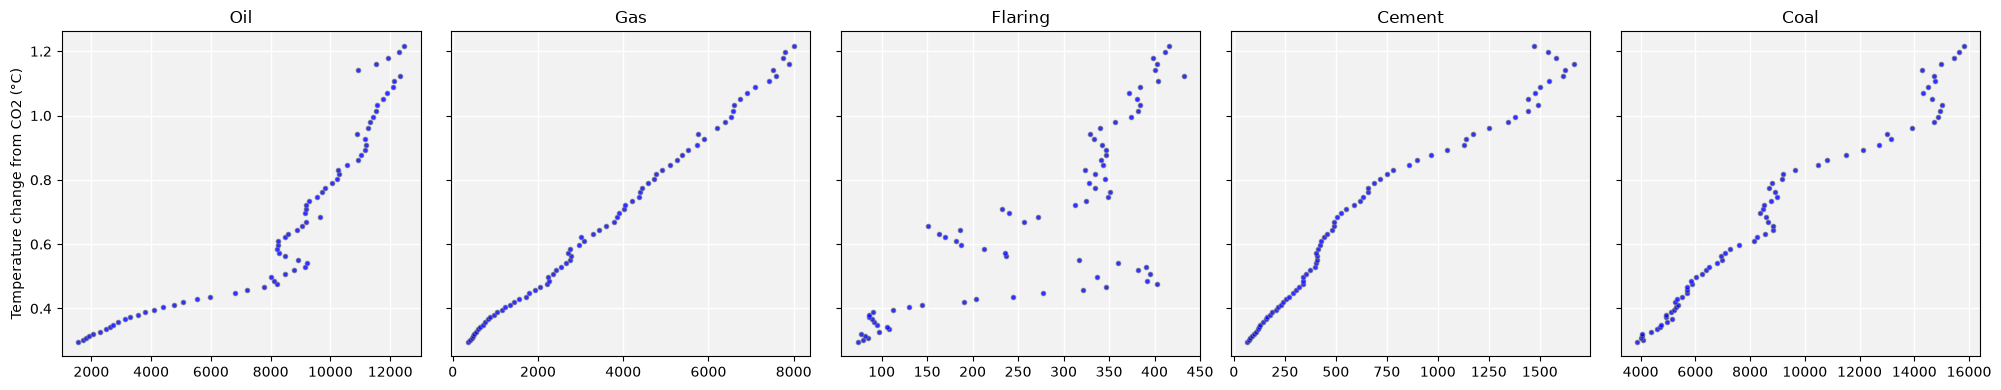

In [5]:
sources = ["oil_co2", "gas_co2", "flaring_co2", "cement_co2", "coal_co2"]

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for ax, col in zip(axes, sources):
    ax.scatter(
        world_co2_df[col],
        world_co2_df["temperature_change_from_co2"],
        c="blue",  # color of the points
        s=12,  # size of the points
        edgecolor="grey",  # edge color of the points
        linewidth=0.6,  # edge line width of the points
        alpha=0.8,  # transparency of the points
    )
    ax.set_title(col.replace("_co2", "").capitalize())
axes[0].set_ylabel("Temperature change from CO2 (°C)")

fig.set_facecolor("white")  # the whole figure (outside the axes)
for ax in axes:
    ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)
    ax.grid(color="white", linewidth=1)
    ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

## 5. Build Linear Models for Regression

In [6]:
# Split the data into training (70%) and test sets (30%)

from sklearn.model_selection import train_test_split

X = world_co2_df.loc[:, "oil_co2"]
y = world_co2_df.loc[:, "temperature_change_from_co2"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print(
    f"X_train shape: {X_train.shape}, percentage of training data: {X_train.shape[0] / X.shape[0]:.2%}"
)
print(
    f"X_test shape: {X_test.shape}, percentage of test data: {X_test.shape[0] / X.shape[0]:.2%}"
)

X_train shape: (52,), percentage of training data: 69.33%
X_test shape: (23,), percentage of test data: 30.67%


In [7]:
# Standardize the features using StandardScaler

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train.values.reshape(-1, 1))
X_test_scaled = scaler.transform(X_test.values.reshape(-1, 1))

In [8]:
from sklearn.linear_model import LinearRegression

# Fit a linear regression model to the standardized training data
lr = LinearRegression().fit(X_train_scaled, y_train)

# Make predictions on the standardized test data
y_pred = lr.predict(X_test_scaled)
print(f"Predictions on the test set: {y_pred}")

# Training and test set scores
print(f"Training set score: {lr.score(X_train_scaled, y_train):.4f}")
print(f"Test set score: {lr.score(X_test_scaled, y_test):.4f}")

Predictions on the test set: [0.19705183 0.93327079 0.27997128 0.15795892 0.67892614 0.91720583
 0.74786968 0.31407239 0.99623676 0.93678803 0.67823313 0.74949829
 0.82026426 0.4673428  0.26267708 0.64135361 0.2161378  0.6763648
 0.90419532 0.96311964 0.74037421 0.75274928 0.40748568]
Training set score: 0.8047
Test set score: 0.8546


Linear regression model:

$ y = w * z + b $

- $z$ - (oil_co2 - mean) / std
- $w$ - `lr.coef_`
- $b$ - `lr.intercept_`

In [9]:
# Fitting equation on the standardized feature: y = w * z + b, where z = (oil_co2 - mean) / std
w, b = lr.coef_[0], lr.intercept_
print(f"Standardized:  temperature_change = {w:.4f} * z_oil_co2 + {b:.4f}")

# Convert back to the original units: y = (w / std) * oil_co2 + (b - w * mean / std)
mean, std = scaler.mean_[0], scaler.scale_[0]
print(
    f"Original:      temperature_change = {w / std:.4e} * oil_co2 + {b - w * mean / std:.4f}"
)

Standardized:  temperature_change = 0.2434 * z_oil_co2 + 0.6912
Original:      temperature_change = 7.7805e-05 * oil_co2 + 0.0372


Notes: The model was trained on standardized oil CO2, so `lr.coef_` and `lr.intercept_`
on their own give the first equation, written in terms of `z` (oil CO2 minus its `mean`,
divided by its `standard deviation`). The second line uses the scaler's mean and standard
deviation to convert it back to raw oil_co2 (million tonnes).
That version is easier to read: about 7.8×10⁻⁵ (0.000078) °C of warming per million tonnes of oil CO2.

Standardized `oil_co2` fitting model:
$temperature\_change = 0.2434 * (\frac{oil\_co2 - mean}{std}) + 0.6912$

Original `oil_co2` fitting model:
$temperature\_change = 7.7805 * 10^{-5} * oil\_co2 + 0.0372$

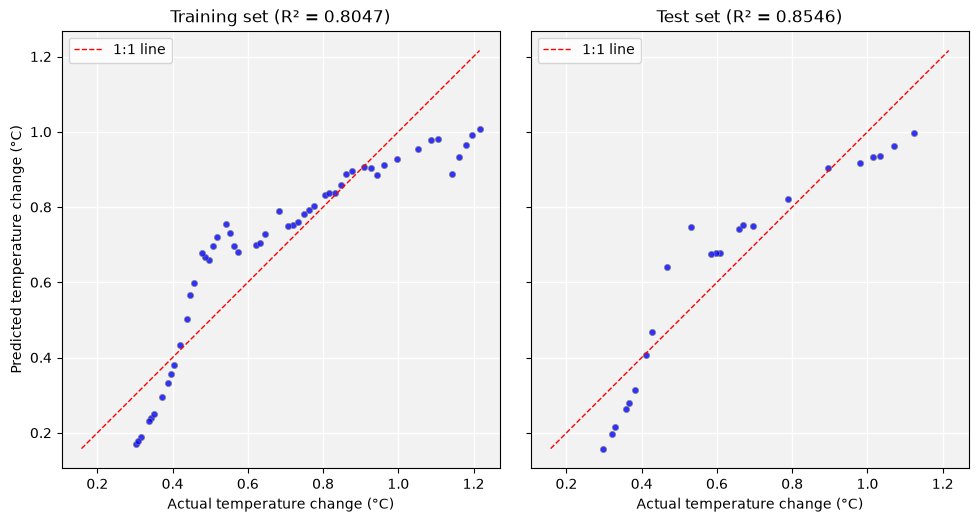

In [10]:
# Crossplots of actual vs. predicted values for the training and test sets
y_train_pred = lr.predict(X_train_scaled)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
for ax, X_set, y_true, y_hat, name in zip(
    axes,
    [X_train_scaled, X_test_scaled],
    [y_train, y_test],
    [y_train_pred, y_pred],
    ["Training", "Test"],
):
    ax.scatter(
        y_true,
        y_hat,
        c="blue",
        s=20,
        edgecolor="grey",
        linewidth=0.6,
        alpha=0.8,
    )
    ax.set_title(f"{name} set (R² = {lr.score(X_set, y_true):.4f})")
    ax.set_xlabel("Actual temperature change (°C)")

# 1:1 line: points on this line are perfect predictions
lims = [
    min(y.min(), y_train_pred.min(), y_pred.min()),
    max(y.max(), y_train_pred.max(), y_pred.max()),
]
for ax in axes:
    ax.plot(lims, lims, color="red", linestyle="--", linewidth=1, label="1:1 line")
    ax.set_aspect("equal")
    ax.legend()
axes[0].set_ylabel("Predicted temperature change (°C)")

fig.set_facecolor("white")
for ax in axes:
    ax.set_facecolor("#f2f2f2")
    ax.grid(color="white", linewidth=1)
    ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

## 6. Compared Different Regression Models

In [11]:
# Split the data into training (70%) and test sets (30%)

from sklearn.model_selection import train_test_split

X = world_co2_df.loc[:, "oil_co2"]
y = world_co2_df.loc[:, "temperature_change_from_co2"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print(
    f"X_train shape: {X_train.shape}, percentage of training data: {X_train.shape[0] / X.shape[0]:.2%}"
)
print(
    f"X_test shape: {X_test.shape}, percentage of test data: {X_test.shape[0] / X.shape[0]:.2%}"
)

# Standardize the features using StandardScaler

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train.values.reshape(-1, 1))
X_test_scaled = scaler.transform(X_test.values.reshape(-1, 1))

X_train shape: (52,), percentage of training data: 69.33%
X_test shape: (23,), percentage of test data: 30.67%


In [12]:
from sklearn.linear_model import BayesianRidge, Lasso, LinearRegression, Ridge

# Fit a linear regression model to the standardized training data
lr = LinearRegression().fit(X_train_scaled, y_train)
rd = Ridge().fit(X_train_scaled, y_train)
lo = Lasso().fit(X_train_scaled, y_train)
br = BayesianRidge().fit(X_train_scaled, y_train)

# Training and test set scores
lr_train_score = round(lr.score(X_train_scaled, y_train), 4)
lr_test_score = round(lr.score(X_test_scaled, y_test), 4)
rd_train_score = round(rd.score(X_train_scaled, y_train), 4)
rd_test_score = round(rd.score(X_test_scaled, y_test), 4)
lo_train_score = round(lo.score(X_train_scaled, y_train), 4)
lo_test_score = round(lo.score(X_test_scaled, y_test), 4)
br_train_score = round(br.score(X_train_scaled, y_train), 4)
br_test_score = round(br.score(X_test_scaled, y_test), 4)

scores_df = pd.DataFrame(
    [
        {
            "Model": "Linear Regression",
            "Training Score": lr_train_score,
            "Test Score": lr_test_score,
        },
        {
            "Model": "Ridge",
            "Training Score": rd_train_score,
            "Test Score": rd_test_score,
        },
        {
            "Model": "Lasso",
            "Training Score": lo_train_score,
            "Test Score": lo_test_score,
        },
        {
            "Model": "Bayesian Ridge",
            "Training Score": br_train_score,
            "Test Score": br_test_score,
        },
    ]
)

print(scores_df)

               Model  Training Score  Test Score
0  Linear Regression          0.8047      0.8546
1              Ridge          0.8044      0.8584
2              Lasso          0.0000     -0.0451
3     Bayesian Ridge          0.8047      0.8556


## 7. Build Multi-Variables Linear Regression Model

$ y = w_1 * x_1 + w_2 * x_2 + ... + b $

- $x_1, x_2, ...$: input variables
- $w_1, w_2, ...$: fitting coefficient for each input
- $b$: intercept

5 input variables:
- oil_co2
- gas_co2
- coal_co2
- flaring_co2
- cement_co2


In [13]:
# Split the data into training (70%) and test sets (30%)

from sklearn.model_selection import train_test_split

X = world_co2_df.loc[:, "oil_co2":"cement_co2"]
y = world_co2_df.loc[:, "temperature_change_from_co2"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print(
    f"X_train shape: {X_train.shape}, percentage of training data: {X_train.shape[0] / X.shape[0]:.2%}"
)
print(
    f"X_test shape: {X_test.shape}, percentage of test data: {X_test.shape[0] / X.shape[0]:.2%}"
)

X_train shape: (52, 5), percentage of training data: 69.33%
X_test shape: (23, 5), percentage of test data: 30.67%


In [14]:
# Standardize the features using StandardScaler

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [15]:
from sklearn.linear_model import LinearRegression

# Fit a linear regression model to the standardized training data
lr = LinearRegression().fit(X_train_scaled, y_train)

# Make predictions on the standardized test data
y_pred = lr.predict(X_test_scaled)
print(f"Predictions on the test set: {y_pred}")

# Training and test set scores
print(f"Training set score: {lr.score(X_train_scaled, y_train):.4f}")
print(f"Test set score: {lr.score(X_test_scaled, y_test):.4f}")

Predictions on the test set: [0.32328669 1.01888263 0.35926549 0.30758635 0.61455399 0.99983519
 0.5225005  0.37394899 1.13791169 1.02157903 0.59864546 0.70948563
 0.78432912 0.43029416 0.35050824 0.47055854 0.32644565 0.56692097
 0.8943518  1.06120908 0.67866356 0.69431712 0.41063119]
Training set score: 0.9985
Test set score: 0.9983


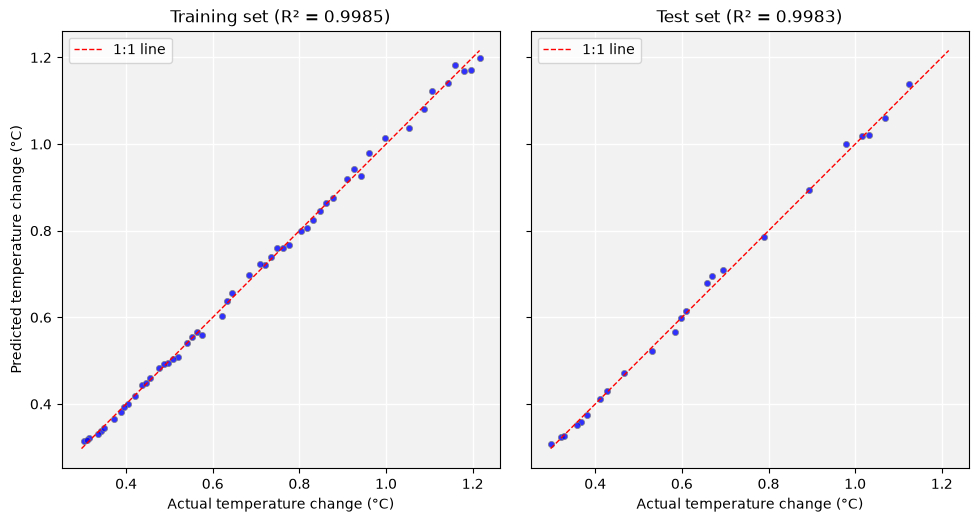

In [16]:
# Crossplots of actual vs. predicted values for the training and test sets
y_train_pred = lr.predict(X_train_scaled)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
for ax, X_set, y_true, y_hat, name in zip(
    axes,
    [X_train_scaled, X_test_scaled],
    [y_train, y_test],
    [y_train_pred, y_pred],
    ["Training", "Test"],
):
    ax.scatter(
        y_true,
        y_hat,
        c="blue",
        s=20,
        edgecolor="grey",
        linewidth=0.6,
        alpha=0.8,
    )
    ax.set_title(f"{name} set (R² = {lr.score(X_set, y_true):.4f})")
    ax.set_xlabel("Actual temperature change (°C)")

# 1:1 line: points on this line are perfect predictions
lims = [
    min(y.min(), y_train_pred.min(), y_pred.min()),
    max(y.max(), y_train_pred.max(), y_pred.max()),
]
for ax in axes:
    ax.plot(lims, lims, color="red", linestyle="--", linewidth=1, label="1:1 line")
    ax.set_aspect("equal")
    ax.legend()
axes[0].set_ylabel("Predicted temperature change (°C)")

fig.set_facecolor("white")
for ax in axes:
    ax.set_facecolor("#f2f2f2")
    ax.grid(color="white", linewidth=1)
    ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

In [17]:
w, b = lr.coef_, lr.intercept_
print(f"Fitting coefficients for each feature: {', '.join([f'{wi:.4f}' for wi in w])}")
print(f"Intercept: {b:.4f}")

Fitting coefficients for each feature: -0.0178, 0.3021, 0.0017, -0.0079, -0.0107
Intercept: 0.6912


In [18]:
# Fitting equation on the standardized features: y = w1 * z1 + w2 * z2 + ... + b, where z_i = (x_i - mean_i) / std_i
# With 5 inputs, lr.coef_ is an array of 5 weights, so format each one separately
features = X.columns
w, b = lr.coef_, lr.intercept_
terms = " + ".join(f"{w_i:.4f} * z_{name}" for w_i, name in zip(w, features))
print(f"Standardized:  temperature_change = {terms} + {b:.4f}")

# Convert back to the original units: w_i / std_i for each input, and b - sum(w_i * mean_i / std_i)
mean, std = scaler.mean_, scaler.scale_
w_orig = w / std
b_orig = b - np.sum(w * mean / std)
terms = " + ".join(f"{w_i:.4e} * {name}" for w_i, name in zip(w_orig, features))
print(f"Original:      temperature_change = {terms} + {b_orig:.4f}")

Standardized:  temperature_change = -0.0178 * z_oil_co2 + 0.3021 * z_gas_co2 + 0.0017 * z_coal_co2 + -0.0079 * z_flaring_co2 + -0.0107 * z_cement_co2 + 0.6912
Original:      temperature_change = -5.6759e-06 * oil_co2 + 1.3109e-04 * gas_co2 + 4.5236e-07 * coal_co2 + -7.2182e-05 * flaring_co2 + -2.2001e-05 * cement_co2 + 0.2751
